In [22]:
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd
from sklearn.model_selection import train_test_split
import seaborn as sns

In [5]:
insurance_data = pd.read_csv("insurance.csv")

In [6]:
insurance_data

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [9]:
X = insurance_data.drop(columns = ["charges"])
y = insurance_data["charges"]

X = pd.get_dummies(X, columns = ["region"], drop_first = True, dtype = int)

X["sex"] = X["sex"].map(
    {
        "female" : 1, 
        "male" : 0
    })

X["smoker"] = X["smoker"].map(
    {
        "yes" : 1, 
        "no" : 0
    })

X["age_smoker"] = X["age"] * X["smoker"]
X["bmi_smoker"] = X["bmi"] * X["smoker"]

In [10]:
X.head(10)

,age,sex,bmi,children,smoker,region_northwest,region_southeast,region_southwest,age_smoker,bmi_smoker
0,19,1,27.900,0,1,0,0,1,19,27.9
1,18,0,33.770,1,0,0,1,0,0,0.0
2,28,0,33.000,3,0,0,1,0,0,0.0
3,33,0,22.705,0,0,1,0,0,0,0.0
4,32,0,28.880,0,0,1,0,0,0,0.0
5,31,1,25.740,0,0,0,1,0,0,0.0
6,46,1,33.440,1,0,0,1,0,0,0.0
7,37,1,27.740,3,0,1,0,0,0,0.0
8,37,0,29.830,2,0,0,0,0,0,0.0
9,60,1,25.840,0,0,1,0,0,0,0.0


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

MSE for alphs 0.001:  20922599.871035974
MSE for alphs 0.1:  20921803.698431384
MSE for alphs 1:  20914832.635089148
MSE for alphs 2:  20908106.779954527
MSE for alphs 5:  20890881.000633504
MSE for alphs 10:  20872844.794796694
MSE for alphs 20:  20877828.53237883
MSE for alphs 30:  20937537.133939773
MSE for alphs 40:  21046489.293890767
MSE for alphs 50:  21196929.869608898
MSE for alphs 60:  21396196.939894903
MSE for alphs 70:  21634290.385158457
MSE for alphs 80:  21860927.299760185
MSE for alphs 90:  22131405.232434373
MSE for alphs 100:  22423172.68602322


<Axes: >

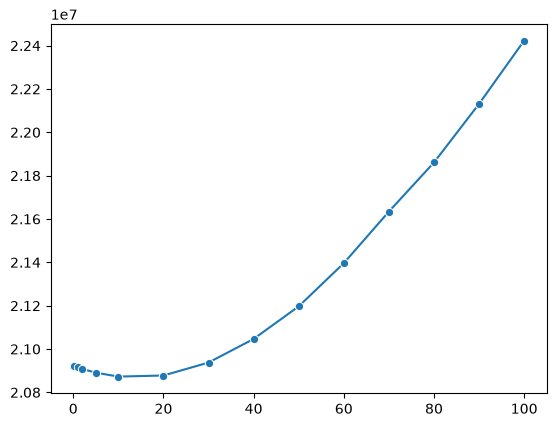

In [17]:
alphas = [0.001, 0.1, 1, 2, 5, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100]
mses = []

for a in alphas:
    lasso_model = Lasso(alpha = a)
    lasso_model.fit(X_train, y_train)
    
    y_pred = lasso_model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    print(f"MSE for alphs {a}: ", mse)
    mses.append(mse)

sns.lineplot(x=alphas, y=mses, marker = "o")

In [23]:
from sklearn.linear_model import LassoCV
a = [0.001, 0.1, 1, 2, 5, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100]

lasso_cv_model = LassoCV(
    alphas = a,
    cv = 5, 
    max_iter = 1000,
    random_state = 42
)

lasso_cv_model.fit(X_train, y_train)
print("best alpha: ", lasso_cv_model.alpha_)
best_alpha = lasso_cv_model.alpha_

y_pred = lasso_cv_model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"MSE for alphs {best_alpha}: ", mse)
print("r2: ", r2)

best alpha:  0.001
MSE for alphs 0.001:  20922599.871035974
r2:  0.8652317499151698
